In [1]:
# geopandas综合练习
# 完成时间：2026-7-13·
# 将OD数据集计到行政区划，并绘制OD期望线

In [2]:
# 导入必要的包
import pandas as pd
import numpy as np

# 绘制图用的包
import matplotlib as mpl
import matplotlib.pyplot as plt

# geopandas包
import geopandas

# shapely包
from shapely.geometry import Point,Polygon,shape

读取基础数据

<Axes: >

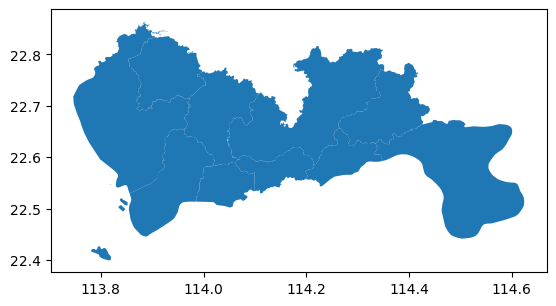

In [3]:
# 行政区划数据
# 读取shapefile文件
shp = r'E:\GIS_Learning\data\sz.shp'
xzqh = geopandas.GeoDataFrame.from_file(shp,encoding = 'utf-8')

# 绘制看看长什么样
xzqh.plot()

<Axes: >

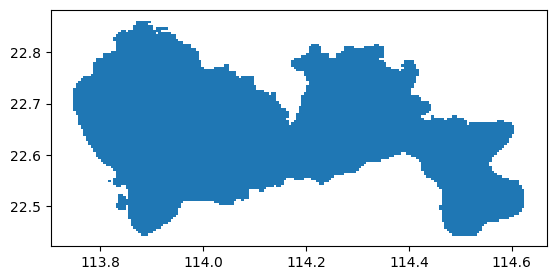

In [4]:
# 栅格数据
# 读取shapefile文件
shp = r'E:\GIS_Learning\data\grid.shp'
grid = geopandas.GeoDataFrame.from_file(shp,encoding = 'gbk')

# 绘制看看长什么样
grid.plot()

栅格OD数据

In [5]:
# 此数据已在前面练习过程中获取
OD = pd.read_csv(r'E:\GIS_Learning\data\taxi_od_grid.csv')
OD.head(5)

,SLONCOL,SLATCOL,ELONCOL,ELATCOL,VehicleNum
0,63,17,65,16,298
1,75,21,74,19,275
2,63,18,65,16,235
3,76,21,74,19,173
4,65,17,63,18,172


栅格与小区、行政区匹配

In [6]:
#栅格所带的字段信息
grid.head(5)

,LONCOL,LATCOL,HBLON,HBLAT,geometry
0,0,54,113.749504,22.688405,"POLYGON ((113.75 22.686, 113.75 22.691, 113.75..."
1,0,55,113.749504,22.692902,"POLYGON ((113.75 22.691, 113.75 22.695, 113.75..."
2,0,56,113.749504,22.697399,"POLYGON ((113.75 22.695, 113.75 22.7, 113.75 2..."
3,0,57,113.749504,22.701895,"POLYGON ((113.75 22.7, 113.75 22.704, 113.75 2..."
4,0,58,113.749504,22.706392,"POLYGON ((113.75 22.704, 113.75 22.709, 113.75..."


In [7]:
"""
我们现在要做的是，将栅格与行政区匹配，希望得到的是，在栅格信息的后面加一列，表示这个栅格属于哪个行政区划
在这里，我们考虑以栅格中心点落在哪个空间单元来判断，比如某栅格中心点落在宝安区，那么认为这个栅格是宝安区的栅格
因此，下一步我们定义一个geoDataFrame变量，命名为grid_point，存储的是栅格的中心点
"""

'\n我们现在要做的是，将栅格与行政区匹配，希望得到的是，在栅格信息的后面加一列，表示这个栅格属于哪个行政区划\n在这里，我们考虑以栅格中心点落在哪个空间单元来判断，比如某栅格中心点落在宝安区，那么认为这个栅格是宝安区的栅格\n因此，下一步我们定义一个geoDataFrame变量，命名为grid_point，存储的是栅格的中心点\n'

<Axes: >

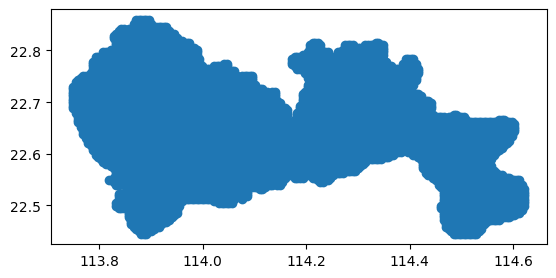

In [8]:
grid_point = grid.copy() # .copy() 会生成一份和原数据完全一致的新数据，后续修改 grid_point 不会破坏原始栅格数据，保证原始数据可复用
# 我们相当于把geometry这一列的信息由polygon改成point
grid_point['geometry'] = grid.centroid # .centroid会自动计算每一个几何对象的质心（中心点），返回一个由 Point 点几何组成的新序列

grid_point.plot()

In [9]:
grid_point.head(5)

,LONCOL,LATCOL,HBLON,HBLAT,geometry
0,0,54,113.749504,22.688405,POINT (113.75 22.688)
1,0,55,113.749504,22.692902,POINT (113.75 22.693)
2,0,56,113.749504,22.697399,POINT (113.75 22.697)
3,0,57,113.749504,22.701895,POINT (113.75 22.702)
4,0,58,113.749504,22.706392,POINT (113.75 22.706)


空间连接sjoin

In [10]:
# 通过空间位置关系，给每个栅格中心点匹配上它所属的行政区划属性，相当于给每个栅格打上 “属于深圳哪个区” 的标签，为后续把栅格 OD 汇总成行政区 OD 做准备

In [11]:
# 连接到行政区划
grid_point = geopandas.sjoin(grid_point, xzqh, how="inner", predicate='intersects')
# how="inner"：内连接模式（控制连接后左右两边能成功匹配的记录，即只有落在深圳行政区划范围内的栅格点会被保留，超出范围的会被剔除）
# predicate='intersects'：空间匹配规则（判定两个几何对象是否匹配的空间谓词，这里用「相交」作为判定条件：对于 “点 - 面” 匹配场景，只要栅格中心点落在行政区面的内部或者边界上
# 就判定为 “相交”，完成匹配。匹配成功后，右表（行政区划）的所有属性字段（比如区名 qh、行政区质心坐标等）会自动拼接到左表对应的行上）
grid_point.head(5)

,LONCOL,LATCOL,HBLON,HBLAT,geometry,index_right,centroid_x,centroid_y,qh
2,0,56,113.749504,22.697399,POINT (113.75 22.697),3,113.851387,22.67912,宝安
3,0,57,113.749504,22.701895,POINT (113.75 22.702),3,113.851387,22.67912,宝安
4,0,58,113.749504,22.706392,POINT (113.75 22.706),3,113.851387,22.67912,宝安
5,0,59,113.749504,22.710888,POINT (113.75 22.711),3,113.851387,22.67912,宝安
6,0,60,113.749504,22.715385,POINT (113.75 22.715),3,113.851387,22.67912,宝安


<Axes: >

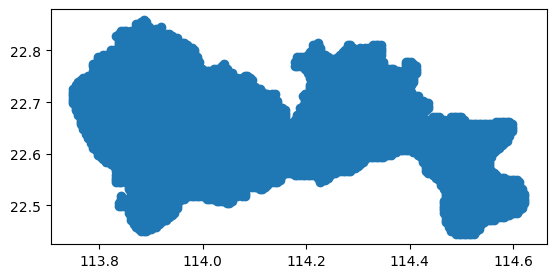

In [12]:
grid_point.plot()

In [13]:
# 仅保留后续业务流程需要的核心字段，剔除所有冗余列
grid_point = grid_point[['LONCOL','LATCOL','qh','centroid_x','centroid_y']]

把OD表的起点终点和grid_point表连接

In [14]:
# 这里我们用df.merge，把OD和grid_point表连接起来
# 两次重命名+表合并，为OD数据的起点和终点匹配上对应的行政区名称、栅格中心点经纬度坐标

In [15]:
"""
pd.merge() 全面详解
标准格式：pd.merge(left, right, on=None, how='inner', left_on=None, right_on=None,suffixes=('_x', '_y'),...)
left：左表（主表），希望保留主体、往上面挂属性的表。right：右表（附表），提供补充属性信息的表。
on：关联键：两张表中列名完全相同的匹配依据字段。可以是单个字符串（单键匹配），也可以是列表（多键联合匹配）
how：连接方式：决定最终结果保留哪些行，是 merge 最核心的参数，默认值为 'inner'。可选值：'inner'（只保留左右表关联键完全匹配成功的行）
/ 'left'(完整保留左表的所有行；右表中匹配成功的行，把属性字段挂上去) / 'right'(和左连接逻辑相反) / 'outer'(保留左右表的所有行，匹配成功的行拼接在一起)
left_on / right_on：当左右表的关联键列名不一致时使用：分别指定左表的关联列名、右表的关联列名
suffixes：当左右表存在非关联键的重名列时，给两表的重名列分别加后缀，避免列名冲突。默认值为 ('_x', '_y')，即左表重名列加_x，右表加_y
"""

"\npd.merge() 全面详解\n标准格式：pd.merge(left, right, on=None, how='inner', left_on=None, right_on=None,suffixes=('_x', '_y'),...)\nleft：左表（主表），希望保留主体、往上面挂属性的表。right：右表（附表），提供补充属性信息的表。\non：关联键：两张表中列名完全相同的匹配依据字段。可以是单个字符串（单键匹配），也可以是列表（多键联合匹配）\nhow：连接方式：决定最终结果保留哪些行，是 merge 最核心的参数，默认值为 'inner'。可选值：'inner'（只保留左右表关联键完全匹配成功的行）\n/ 'left'(完整保留左表的所有行；右表中匹配成功的行，把属性字段挂上去) / 'right'(和左连接逻辑相反) / 'outer'(保留左右表的所有行，匹配成功的行拼接在一起)\nleft_on / right_on：当左右表的关联键列名不一致时使用：分别指定左表的关联列名、右表的关联列名\nsuffixes：当左右表存在非关联键的重名列时，给两表的重名列分别加后缀，避免列名冲突。默认值为 ('_x', '_y')，即左表重名列加_x，右表加_y\n"

In [16]:
grid_point.columns = ['SLONCOL','SLATCOL','Sqh','S_x','S_y'] # 将 grid_point 表的 5 个列名，批量替换为 S 开头的新名称
# 下一步要和 OD 表的起点字段做合并，要求两张表的关联列名完全一致

OD = pd.merge(OD,grid_point,on = ['SLONCOL','SLATCOL']) # 以 SLONCOL（起点栅格列号）、SLATCOL（起点栅格行号）两个字段作为联合关联键
# 匹配成功后，会把 grid_point 里的 Sqh（起点行政区）、S_x（起点经度）、S_y（起点纬度）三个字段，拼接到 OD 表中

grid_point.columns = ['ELONCOL','ELATCOL','Eqh','E_x','E_y'] # 再次批量重命名 grid_point 的列名，这次替换为 E 开头的名称，对应终点（End）的属性

OD = pd.merge(OD,grid_point,on = ['ELONCOL','ELATCOL']) # 第二次表合并

集计行政区划的OD

In [17]:
"""
df.groupby(
    by=None,          # 分组依据（分组键），最核心参数,支持单列名字符串、列名列表、Series / 数组、字典 / 函数
    axis=0,           # 按行分组（默认），基本不用改
    as_index=True,    # 分组键是否作为结果的行索引，默认 True：分组字段会变成结果的行索引，不再是普通列，加 .reset_index() 把索引变回列（与改为False效果相同）
    sort=True,        # 是否对分组键的结果排序，默认 True：结果会按分组键的字母 / 数字顺序排序。设为 False 可以保留原始数据中的出现顺序，数据量大时能提升性能
    dropna=True       # 是否自动剔除分组键中含空值的组
)
"""

'\ndf.groupby(\n    by=None,          # 分组依据（分组键），最核心参数,支持单列名字符串、列名列表、Series / 数组、字典 / 函数\n    axis=0,           # 按行分组（默认），基本不用改\n    as_index=True,    # 分组键是否作为结果的行索引，默认 True：分组字段会变成结果的行索引，不再是普通列，加 .reset_index() 把索引变回列（与改为False效果相同）\n    sort=True,        # 是否对分组键的结果排序，默认 True：结果会按分组键的字母 / 数字顺序排序。设为 False 可以保留原始数据中的出现顺序，数据量大时能提升性能\n    dropna=True       # 是否自动剔除分组键中含空值的组\n)\n'

In [18]:
# 分组聚合的核心操作：按起点 / 终点的行政区名称 + 中心点坐标分组，对每组的车辆数求和，最终得到每一对行政区之间的总车流量，同时把分组索引还原为普通列
OD = OD.groupby(['Sqh','S_x','S_y','Eqh','E_x','E_y'])['VehicleNum'].sum().reset_index()
# groupby()执行后会按照列表中字段的组合值对数据行进行归类：所有字段值完全相同的行，会被归为同一个分组
# .sum() 聚合函数，对每个分组内的所有 VehicleNum 数值进行累加求和
# .reset_index() 作用是把处理过后的索引字段重新变回普通的数据列，同时生成从 0 开始的默认整数行索引，最终返回一个标准的 DataFrame 表格，方便后续操作

In [19]:
# 只保留跨行政区的出行，即Sqh与Eqh相等的就不要了
OD = OD[~(OD['Sqh']==OD['Eqh'])]
# OD['Sqh'] == OD['Eqh']：对 OD 表的每一行，判断「起点行政区 Sqh」和「终点行政区 Eqh」是否为同一个区
# ~：布尔取反 最终值为 True 的行就是我们要保留的跨区 OD，值为 False 的区内 OD 会被过滤掉

OD的绘制

In [20]:
# 画期望线的时候，我们希望小的先画，大的后画，这样大的OD就会在最上面
OD = OD.sort_values(by = 'VehicleNum')
# sort_values() 是 pandas DataFrame 专门用于按列值排序的方法
# by='VehicleNum'：指定排序的依据列为「车流量」
# 不额外指定参数时，默认 ascending=True，即升序排列（数值从小到大）；空值默认排在结果末尾

OD.head(5)

,Sqh,S_x,S_y,Eqh,E_x,E_y,VehicleNum
30,大鹏,114.502205,22.571337,龙岗,114.206790,22.695694,1
26,大鹏,114.502205,22.571337,宝安,113.851387,22.679120,1
24,大鹏,114.502205,22.571337,坪山,114.356936,22.691020,1
21,坪山,114.356936,22.691020,罗湖,114.143157,22.577605,1
19,坪山,114.356936,22.691020,宝安,113.851387,22.679120,1


开始画图

In [21]:
import matplotlib as mpl
import matplotlib.pyplot as plt

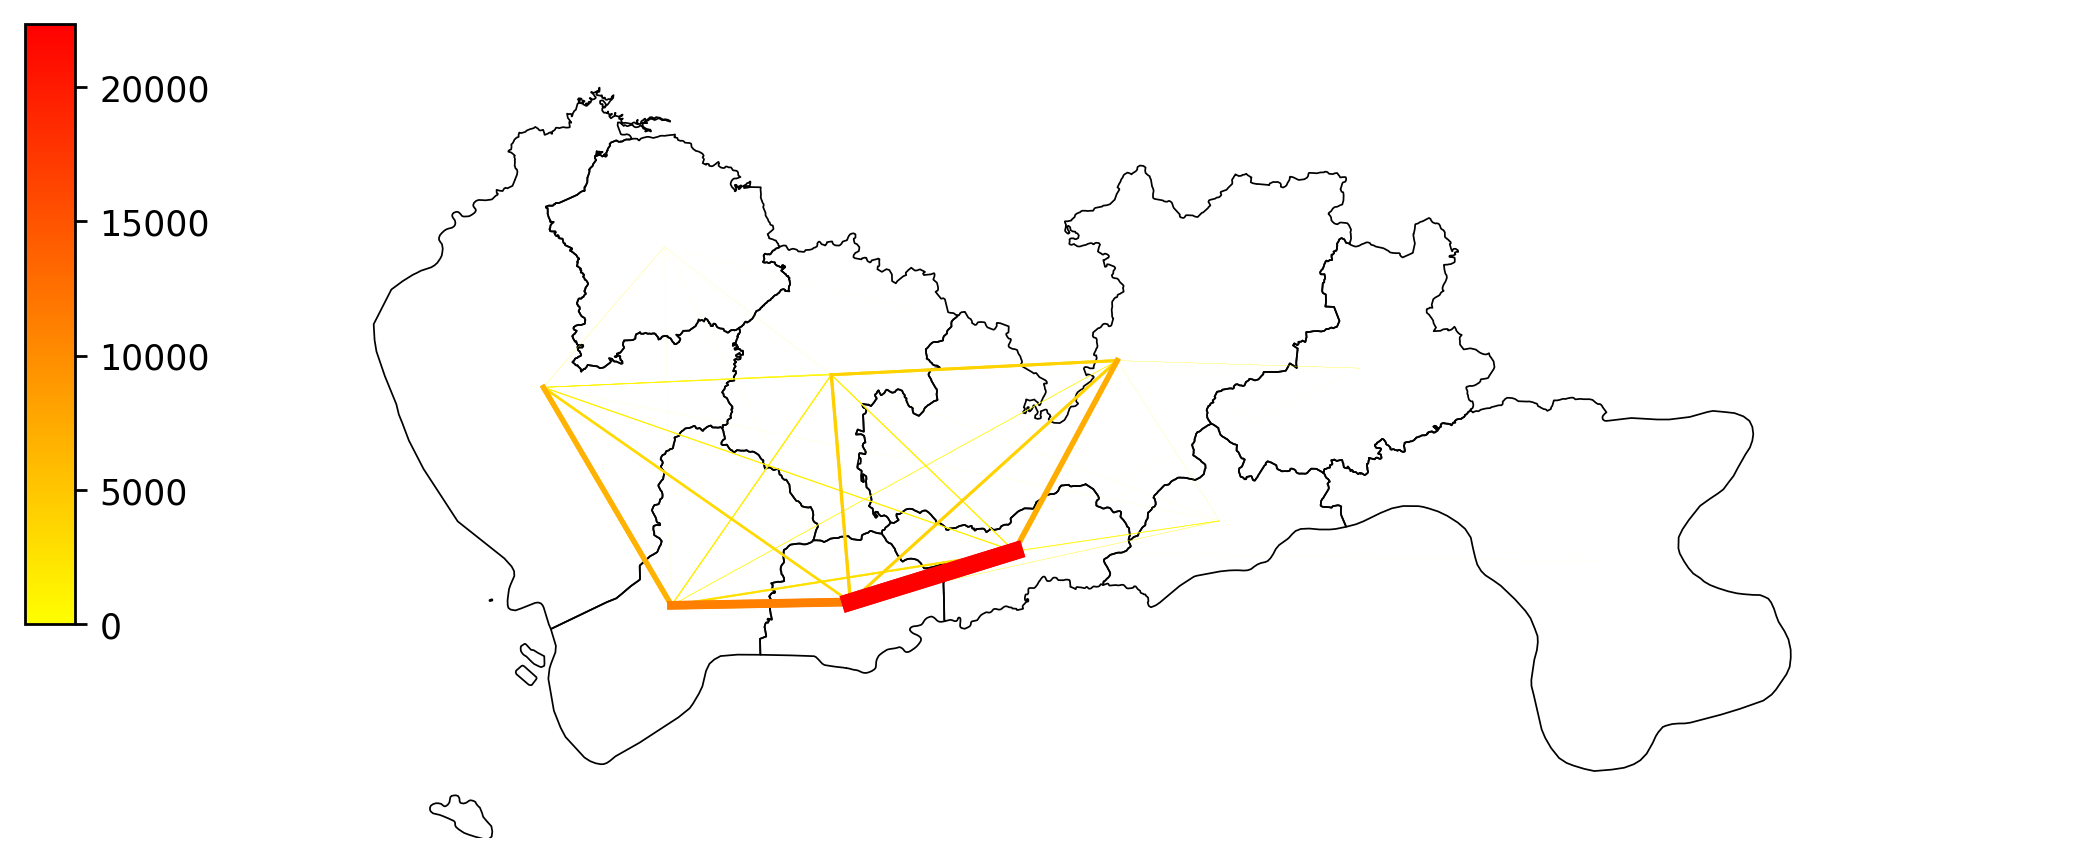

In [22]:
fig     = plt.figure(1,(10,8),dpi = 250)    
ax      = plt.subplot(111)
plt.sca(ax)

# 绘制行政区划
xzqh.plot(ax = ax,edgecolor = (0,0,0,1),facecolor = (0,0,0,0),linewidths=0.5)

# 设置colormap的数据
import matplotlib
vmax = OD['VehicleNum'].max()
# 设定一个标准化的工具，设定OD的colormap最大最小值，他的作用是norm(count)就会将count标准化到0-1的范围内
norm = mpl.colors.Normalize(vmin=0,vmax=vmax)
# 设定colormap的颜色
cmapname = 'autumn_r'
cmap = matplotlib.colormaps[cmapname] # matplotlib.colormaps[色带名]

# 绘制OD
for i in range(len(OD)):
    # 设定第i条线的color和linewidth
    color_i=cmap(norm(OD['VehicleNum'].iloc[i]))
    linewidth_i=norm(OD['VehicleNum'].iloc[i])*5
    
    # 绘制
    plt.plot([OD['S_x'].iloc[i],OD['E_x'].iloc[i]],[OD['S_y'].iloc[i],OD['E_y'].iloc[i]],color=color_i,linewidth=linewidth_i)


    
# 不显示坐标轴
plt.axis('off')    

# 绘制假的colorbar，这是因为，我们画的OD是线，没办法直接画出来colorbar
# 所以我们在一个看不见的地方画了一个叫imshow的东西，他的范围是0到vmax
# 然后我们再对imshow添加colorbar
plt.imshow([[0,vmax]], cmap=cmap) # imshow本来用于绘制二维栅格 / 图像。这里传入一个只有 1 行 2 列的二维数组[[0, vmax]]，使用和 OD 线完全一致的色带
# 设定colorbar的大小和位置
cax = plt.axes([0.08, 0.4, 0.02, 0.3]) # 动创建一个独立的小坐标系，用于放置色条。参数是[左, 下, 宽, 高]
plt.colorbar(cax=cax) # 将色条绘制到刚才创建的cax小坐标系中

# 然后要把镜头调整回到深圳地图那，不然镜头就在imshow那里了

ax.set_xlim(113.6,114.8)
ax.set_ylim(22.4,22.9)


plt.show()

In [23]:
import plot_map

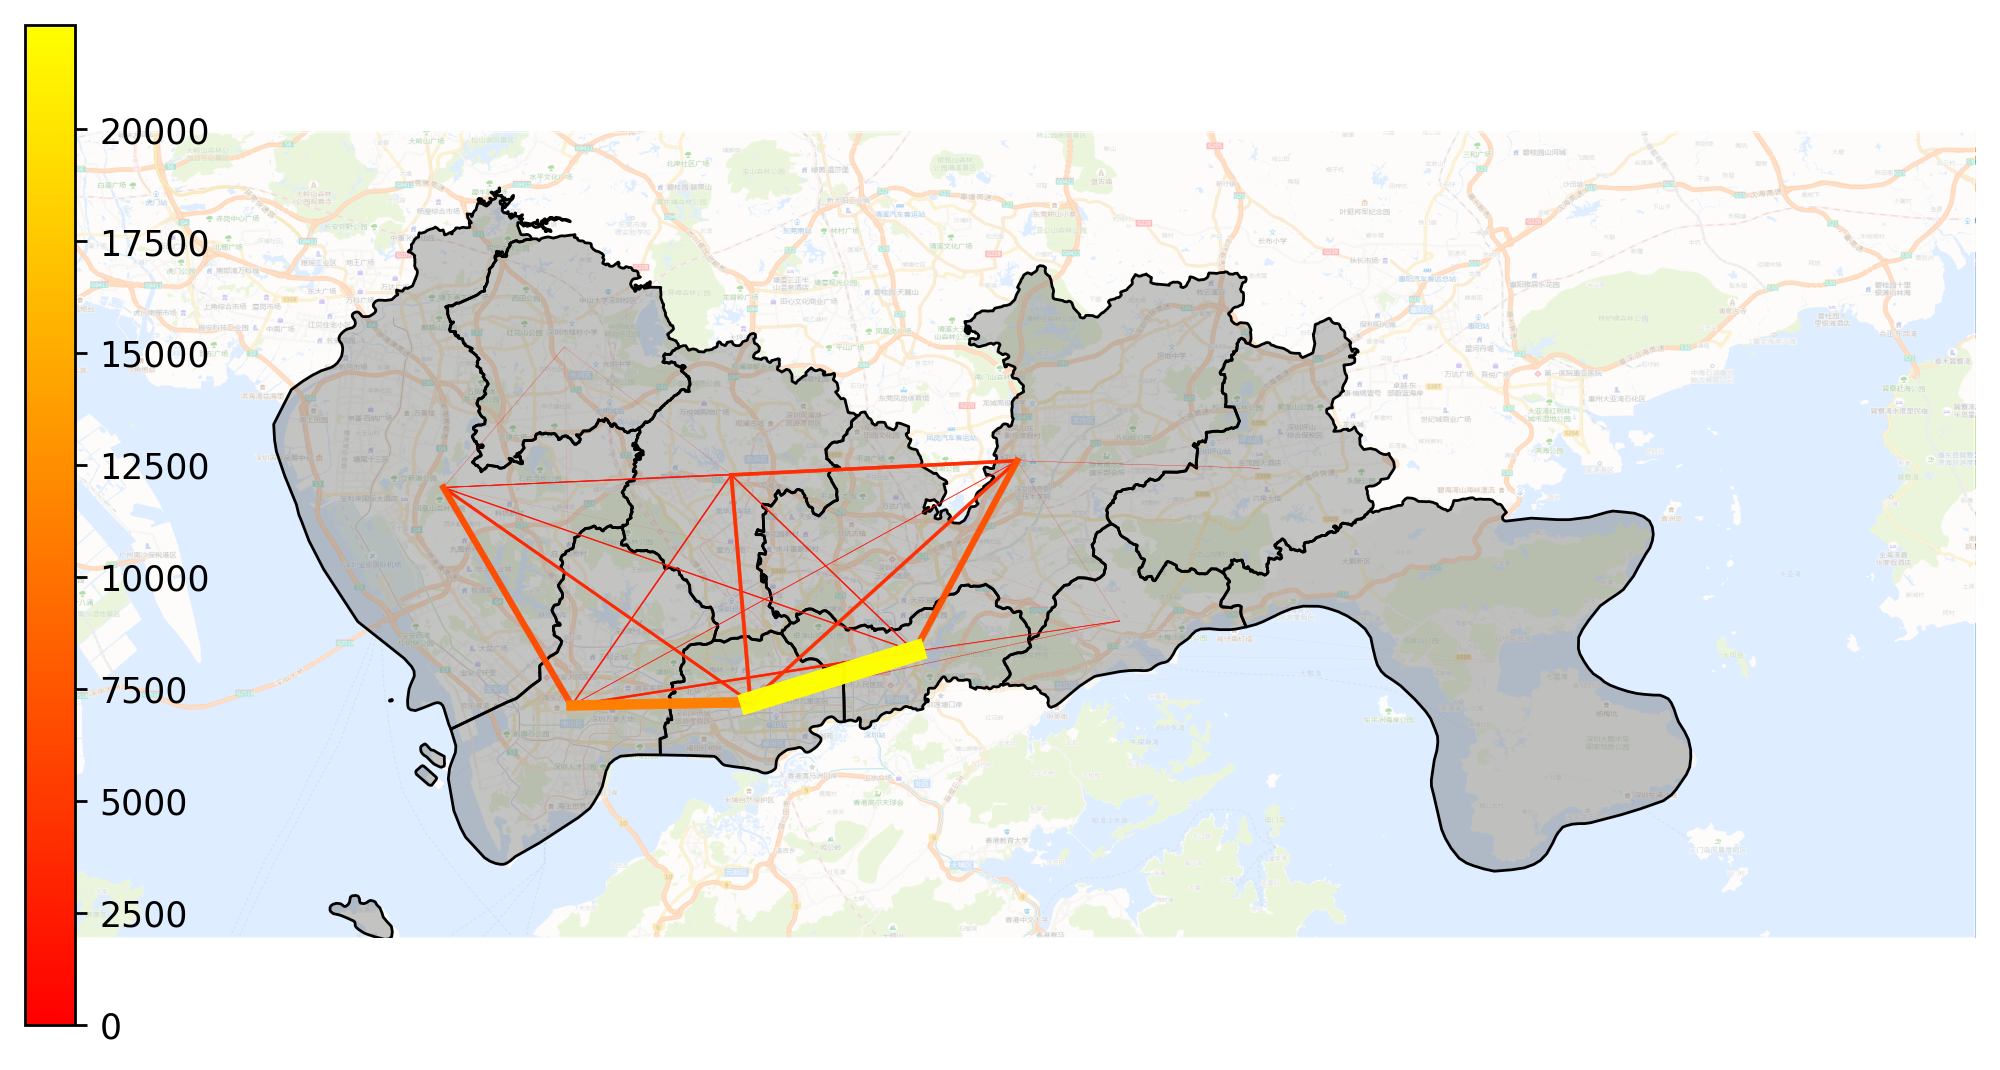

In [24]:
import plot_map
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# 1. 初始化画布
fig = plt.figure(1, (10, 8), dpi=250)
ax = plt.subplot(111)
plt.sca(ax)

"""
plot_map(plt,bounds,zoom = 9,style = 1)
可以通过更改函数plot_map中的"style"和"styleid"来更改地图样式
bounds——设置绘图边界[lon1, lat1, lon2, lat2]即[最小经度, 最小纬度, 最大经度, 最大纬度], 也就是 [左, 下, 右, 上] (wgs1984)
zoom——地图的缩放级别，数值越大，地图细节越丰富、瓦片数量越多、加载越慢。12是常用级别
style——从1到7表示不同的地图样式，1-6表示openstreetmap，7表示mapbox，样式3和4不需要token
style地图样式编号——如果style设置为7（来自mapbox），则可以在此处更改styleid，用“深色”或“浅色”或您自己的样式
"""

# 2. 绘制高德底图
bounds = [113.6, 22.4, 114.8, 22.9]
plot_map.plot_map(plt, bounds, zoom=12, style=4)

# 叠加白色半透明蒙版，把彩色底图压成浅灰色，匹配示例风格
white_mask = Rectangle(
    (bounds[0], bounds[1]), bounds[2]-bounds[0], bounds[3]-bounds[1],
    color='white', alpha=0.65, transform=ax.transData, zorder=1
)
ax.add_patch(white_mask)

# 3. 绘制行政区划：浅灰半透明填充 + 黑色边界
xzqh.plot(
    ax=ax,
    edgecolor=(0, 0, 0, 1),
    facecolor=(0.35, 0.35, 0.35, 0.35),
    linewidths=0.8,
    zorder=2
)

# 4. 配置颜色映射：黄→红渐变，数值越大越红
vmax = OD['VehicleNum'].max()
norm = matplotlib.colors.Normalize(vmin=0, vmax=vmax)
cmap = matplotlib.colormaps['autumn']

# 5. 循环绘制OD线段
for i in range(len(OD)):
    flow = OD['VehicleNum'].iloc[i]
    color_i = cmap(norm(flow))
    linewidth_i = norm(flow) * 6
    plt.plot(
        [OD['S_x'].iloc[i], OD['E_x'].iloc[i]],
        [OD['S_y'].iloc[i], OD['E_y'].iloc[i]],
        color=color_i,
        linewidth=linewidth_i,
        alpha=0.85,
        zorder=3
    )

# 6. 隐藏坐标轴
plt.axis('off')

# 7. 左侧色条（标准写法，方向和示例完全一致）
sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cax = plt.axes([0.12, 0.25, 0.02, 0.5])
plt.colorbar(sm, cax=cax)

# 8. 锁定坐标范围
ax.set_xlim(113.6, 114.8)
ax.set_ylim(22.4, 22.9)

plt.show()